In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve
)

import joblib
from pathlib import Path

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test_data.csv to test_data.csv
Saving train_data.csv to train_data.csv


In [ ]:
train_df = pd.read_csv("train_data.csv")
test_df = pd.read_csv("test_data.csv")

X_train = train_df.drop(columns=["Churn"])
y_train = train_df["Churn"]

X_test = test_df.drop(columns=["Churn"])
y_test = test_df["Churn"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Predict churn probabilities
y_prob = final_model.predict_proba(X_test)[:, 1]

# Use the previously selected threshold
threshold = 0.35
y_pred = (y_prob >= threshold).astype(int)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.77      1409

ROC-AUC: 0.8419


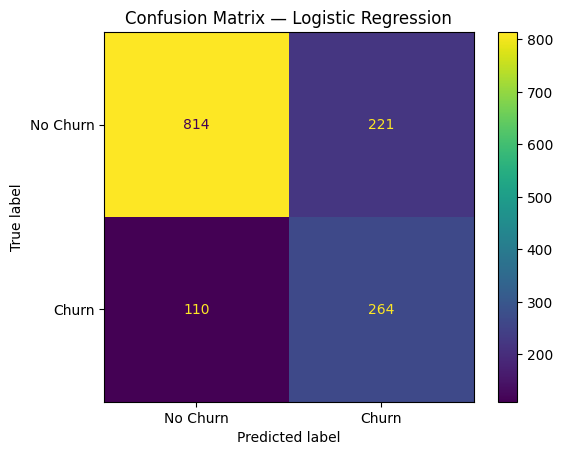

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — Logistic Regression")
plt.show()

In [ ]:
# Combine training and test data for descriptive analysis
# These are the original customer records, not model predictions.
analysis_df = pd.concat(
    [train_df, test_df],
    ignore_index=True
)

analysis_df["Churn"] = analysis_df["Churn"].map(
    {0: "No", 1: "Yes"}
)

def churn_summary(data, column):
    result = (
        data.groupby(column, dropna=False)
        .agg(
            Total_Customers=("Churn", "size"),
            Churned_Customers=("Churn", lambda s: (s == "Yes").sum())
        )
        .reset_index()
    )

    result["Churn_Rate_%"] = (
        result["Churned_Customers"]
        / result["Total_Customers"] * 100
    ).round(2)

    return result.sort_values(
        "Churn_Rate_%", ascending=False
    )

segments = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "Dependents"
]

for column in segments:
    print(f"\nChurn by {column}")
    display(churn_summary(analysis_df, column))


Churn by Contract


,Contract,Total_Customers,Churned_Customers,Churn_Rate_%
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83



Churn by InternetService


,InternetService,Total_Customers,Churned_Customers,Churn_Rate_%
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40



Churn by PaymentMethod


...

,OnlineSecurity,Total_Customers,Churned_Customers,Churn_Rate_%
0,No,3498,1461,41.77
2,Yes,2019,295,14.61
1,No internet service,1526,113,7.40



Churn by PaperlessBilling


,PaperlessBilling,Total_Customers,Churned_Customers,Churn_Rate_%
1,Yes,4171,1400,33.57
0,No,2872,469,16.33



Churn by Dependents


,Dependents,Total_Customers,Churned_Customers,Churn_Rate_%
0,No,4933,1543,31.28
1,Yes,2110,326,15.45


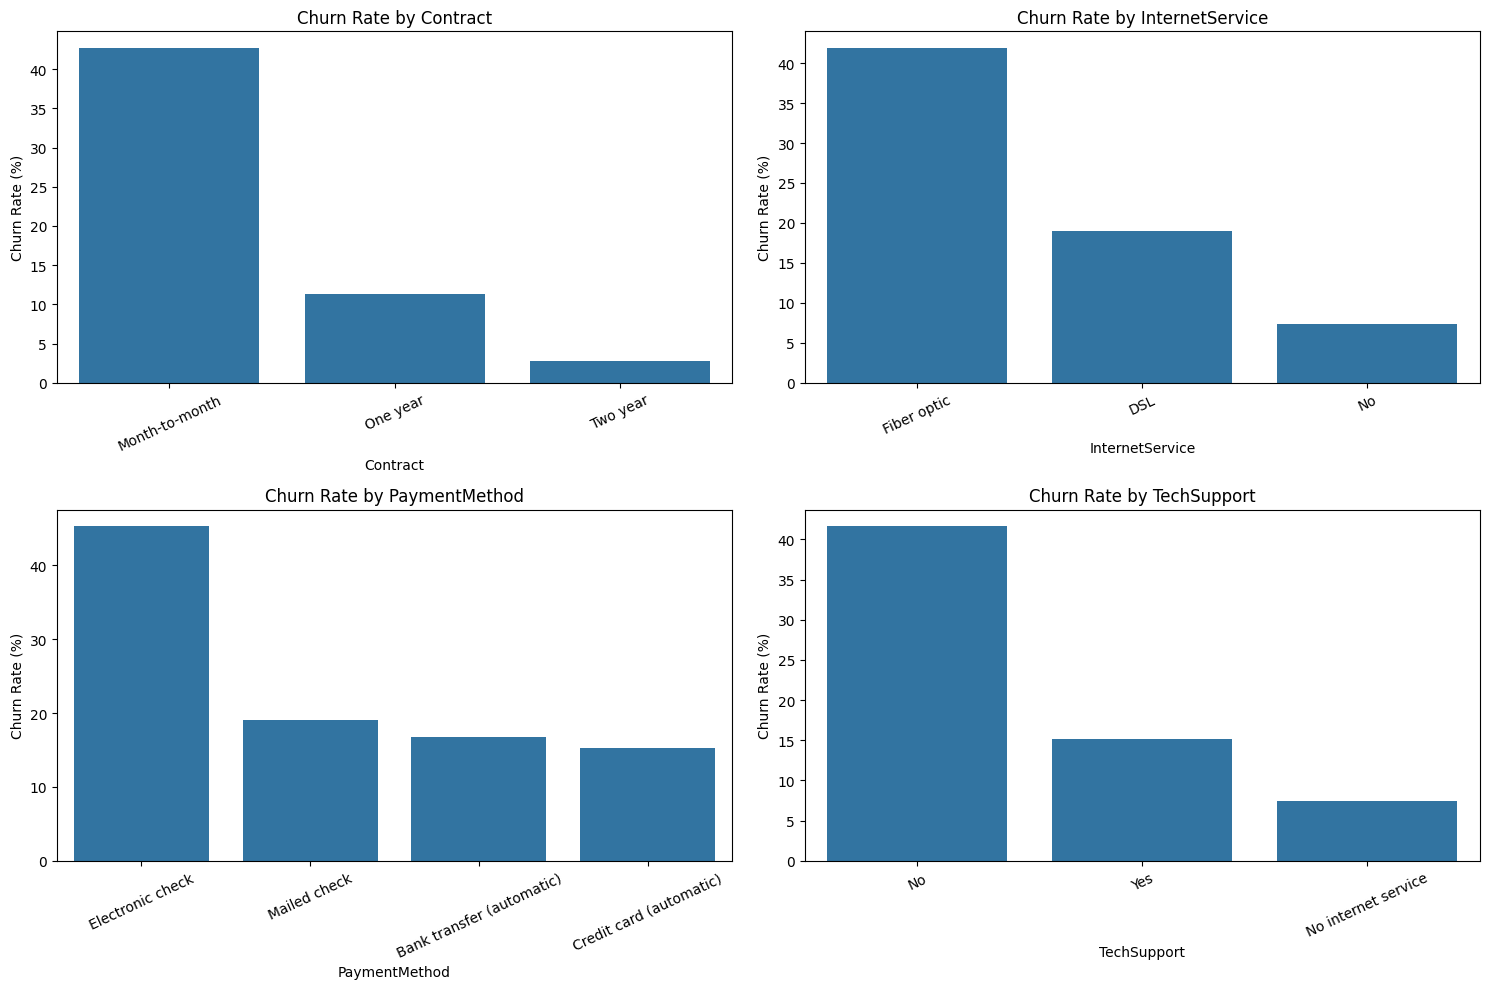

In [ ]:
plot_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, column in zip(axes.flat, plot_columns):
    summary = churn_summary(analysis_df, column)

    sns.barplot(
        data=summary,
        x=column,
        y="Churn_Rate_%",
        ax=ax
    )

    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

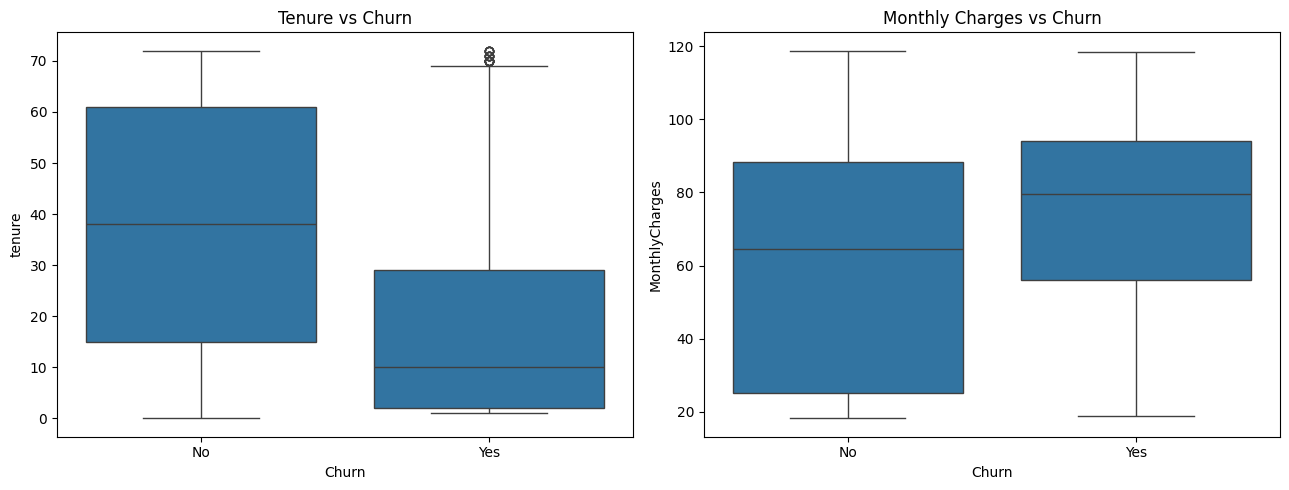

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=analysis_df,
    x="Churn",
    y="tenure",
    ax=axes[0]
)
axes[0].set_title("Tenure vs Churn")

sns.boxplot(
    data=analysis_df,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)
axes[1].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

In [ ]:
# Create a customer-level risk analysis table
risk_df = X_test.copy().reset_index(drop=True)

risk_df["Actual_Churn"] = y_test.reset_index(drop=True)

# Model's predicted probability of churn
risk_df["Churn_Probability"] = final_model.predict_proba(
    X_test
)[:, 1]

# Define business risk bands
risk_df["Risk_Category"] = pd.cut(
    risk_df["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

display(
    risk_df[
        ["tenure", "Contract", "MonthlyCharges",
         "Churn_Probability", "Risk_Category", "Actual_Churn"]
    ].head(10)
)

,tenure,Contract,MonthlyCharges,Churn_Probability,Risk_Category,Actual_Churn
0,72,Two year,114.05,0.045294,Low Risk,0
1,8,Month-to-month,100.15,0.684411,High Risk,0
2,41,One year,78.35,0.058721,Low Risk,0
3,18,Month-to-month,78.20,0.401704,Medium Risk,0
4,72,Two year,82.65,0.021548,Low Risk,0
5,21,Month-to-month,99.85,0.603935,High Risk,0
6,21,Month-to-month,99.15,0.449225,Medium Risk,0
7,19,Month-to-month,24.10,0.130055,Low Risk,0
8,61,Two year,19.75,0.002881,Low Risk,0
9,17,Month-to-month,45.05,0.395179,Medium Risk,1


In [ ]:
risk_summary = (
    risk_df.groupby("Risk_Category", observed=False)
    .agg(
        Total_Customers=("Actual_Churn", "size"),
        Actual_Churned=("Actual_Churn", "sum"),
        Average_Churn_Probability=("Churn_Probability", "mean")
    )
    .reset_index()
)

risk_summary["Actual_Churn_Rate_%"] = (
    risk_summary["Actual_Churned"]
    / risk_summary["Total_Customers"] * 100
).round(2)

risk_summary["Average_Churn_Probability"] = (
    risk_summary["Average_Churn_Probability"] * 100
).round(2)

display(risk_summary)

,Risk_Category,Total_Customers,Actual_Churned,Average_Churn_Probability,Actual_Churn_Rate_%
0,Low Risk,866,92,9.45,10.62
1,Medium Risk,334,132,45.04,39.52
2,High Risk,209,150,69.44,71.77


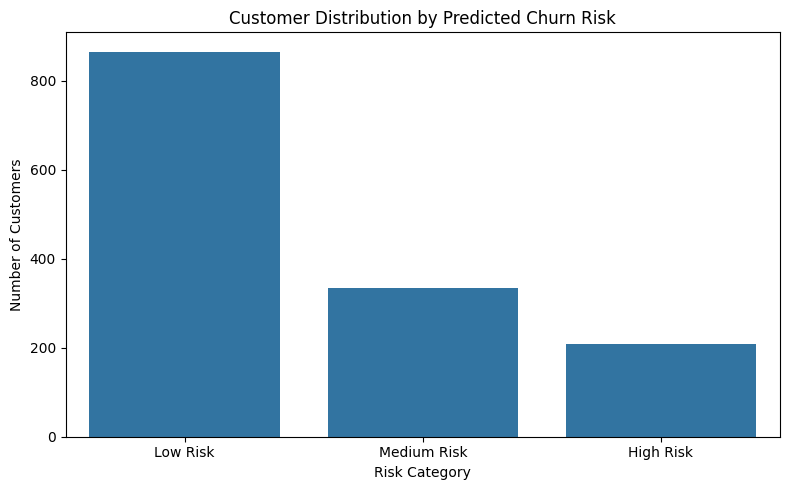

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_df,
    x="Risk_Category",
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Customer Distribution by Predicted Churn Risk")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
high_risk_customers = (
    risk_df[risk_df["Risk_Category"] == "High Risk"]
    .sort_values("Churn_Probability", ascending=False)
)

print("Number of high-risk customers:", len(high_risk_customers))

display(
    high_risk_customers[
        ["tenure", "Contract", "MonthlyCharges",
         "TechSupport", "InternetService", "Churn_Probability"]
    ].head(15)
)


Number of high-risk customers: 209


,tenure,Contract,MonthlyCharges,TechSupport,InternetService,Churn_Probability
1090,1,Month-to-month,95.10,No,Fiber optic,0.855436
1221,1,Month-to-month,95.45,No,Fiber optic,0.832400
1175,7,Month-to-month,99.25,No,Fiber optic,0.828939
1164,7,Month-to-month,101.95,No,Fiber optic,0.822404
1109,1,Month-to-month,85.05,No,Fiber optic,0.819126
889,2,Month-to-month,84.05,No,Fiber optic,0.817964
647,3,Month-to-month,100.95,No,Fiber optic,0.817899
627,3,Month-to-month,96.60,No,Fiber optic,0.817792
1138,3,Month-to-month,105.90,No,Fiber optic,0.816927
1355,4,Month-to-month,83.25,No,Fiber optic,0.812555


In [ ]:
loaded_model = joblib.load(
    PROJECT_DIR / "churn_model.joblib"
)

loaded_threshold = joblib.load(
    PROJECT_DIR / "decision_threshold.joblib"
)

sample_customer = X_test.iloc[[0]]

probability = loaded_model.predict_proba(
    sample_customer
)[0, 1]

prediction = int(probability >= loaded_threshold)

print(f"Churn probability: {probability:.2%}")
print("Prediction:", "Churn" if prediction == 1 else "No Churn")

Churn probability: 4.53%
Prediction: No Churn


In [ ]:
import joblib
from pathlib import Path

PROJECT_DIR = Path("Customer_Churn_Project")
PROJECT_DIR.mkdir(exist_ok=True)

# Save the complete preprocessing + Logistic Regression pipeline
joblib.dump(
    final_model,
    PROJECT_DIR / "churn_model.joblib"
)

# Save the threshold selected using training-only CV predictions
joblib.dump(
    0.35,
    PROJECT_DIR / "decision_threshold.joblib"
)

print("Model and threshold saved successfully!")

Model and threshold saved successfully!


## Business Recommendations

Based on the customer churn analysis and risk segmentation, the following actions are recommended:

1. **Prioritize high-risk customers:** Focus retention efforts on customers classified as high risk, since this segment has an observed churn rate of 71.77%.
2. **Develop targeted retention campaigns:** Offer suitable contract plans, personalized discounts, or service assistance to customers who show a high likelihood of leaving.
3. **Improve customer support:** Investigate whether customers facing technical or service-related problems are more likely to churn.
4. **Encourage long-term contracts:** Analyze whether customers on month-to-month contracts have higher churn rates and test appropriate incentives for longer-term plans.
5. **Monitor churn-risk segments:** Re-evaluate risk groups periodically and track whether retention campaigns reduce actual churn.

These recommendations are hypotheses and potential business actions. Their effectiveness should be validated through controlled retention experiments.

## Project Limitations

- The project uses a single historical telecom customer dataset.
- The model identifies associations and predicts churn; it does not establish the causes of churn.
- Classification threshold selection involves a trade-off between precision and recall.
- The test dataset has been used for multiple model comparisons, so a separate untouched holdout set would be preferable for an unbiased final evaluation.
- The project does not yet estimate the financial cost of churn or the return on investment of retention campaigns.
- Model performance and probability calibration may change when applied to new customers or future data.

## Future Improvements

- Evaluate the model on a separate, untouched test set.
- Tune classification thresholds using cross-validation and business costs.
- Validate probability calibration.
- Deploy the model through a simple web application or API.
- Monitor performance over time and retrain when customer behavior changes.

## Final Project Summary

The Customer Churn Prediction project uses historical telecom customer data to predict whether a customer is likely to discontinue the service.

The workflow includes exploratory data analysis, missing-value handling, categorical encoding, numerical feature scaling, model training, cross-validation, model comparison, classification threshold tuning, and customer risk segmentation.

Three individual classification models—Logistic Regression, Decision Tree, and Random Forest—were compared with a Soft Voting Ensemble. Logistic Regression achieved an F1-score of approximately 0.604 at the default threshold of 0.50. After selecting a threshold of 0.35 using out-of-fold training predictions, the model achieved an F1-score of approximately 0.615 and recall of approximately 0.706 on the previously examined test set.

Customer risk segmentation further divided test-set customers into low-, medium-, and high-risk groups. The observed churn rates were 10.62%, 39.52%, and 71.77%, respectively.

The project demonstrates how machine learning predictions can support customer retention prioritization. The results should be validated on an untouched holdout dataset before being treated as an unbiased estimate of real-world performance.